In [1]:
# imports
import pandas as pd
from getpass import getpass
from urllib.parse import quote_plus
from sqlalchemy import create_engine, text
import matplotlib.pyplot as plt

ds = pd.read_csv('combined_superlotto.csv') 

In [2]:
# read the contents of the combined_superlotto.csv file into a pandas dataframe
ds = pd.read_csv('combined_superlotto.csv') 

In [3]:
ds['Date'] = pd.to_datetime(ds['Date'])


In [4]:
ds.dtypes

Day             object
Date    datetime64[ns]
Draw             int64
N1               int64
N2               int64
N3               int64
N4               int64
N5               int64
Mega             int64
dtype: object

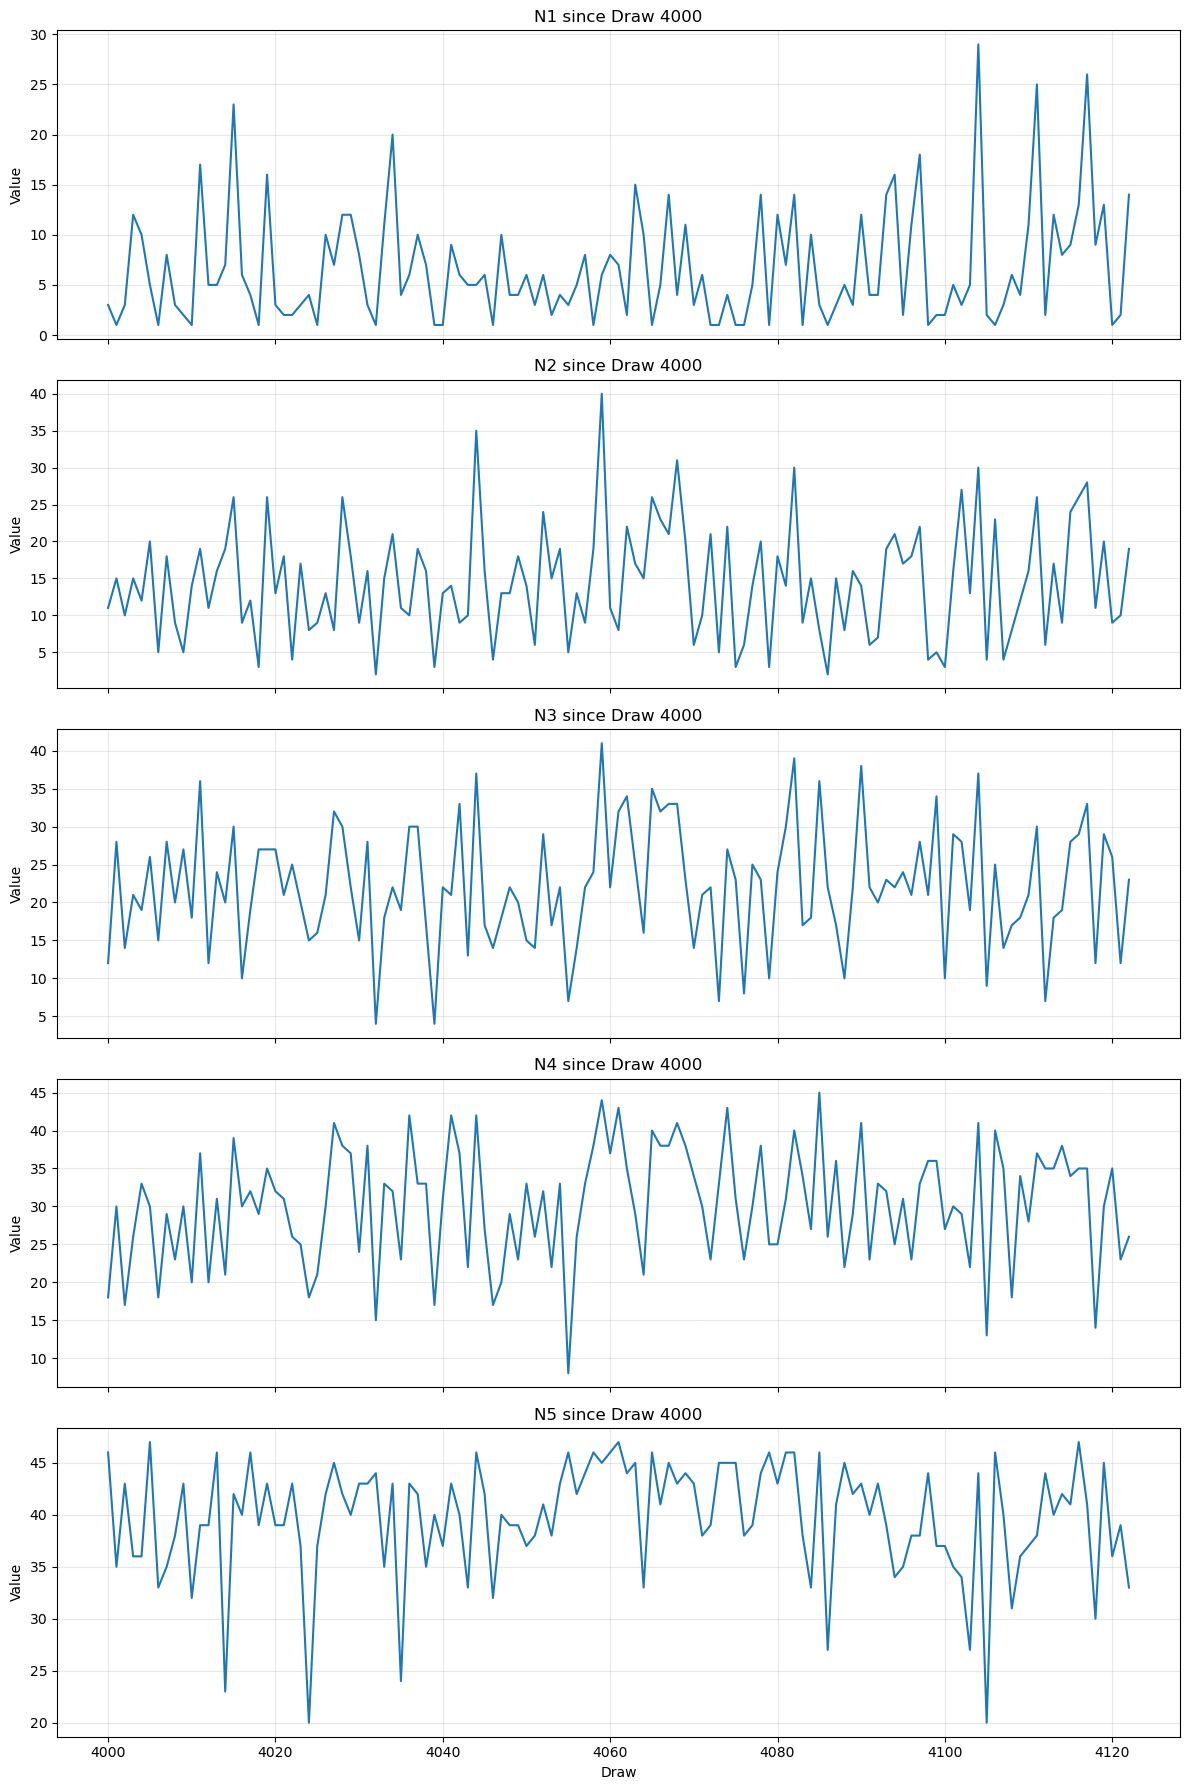

In [ ]:
# Plot N1..N5 and Mega over the same range starting at draw 4000
filtered = ds[ds['Draw'] >= 4000].copy()

fig, axes = plt.subplots(6, 1, figsize=(12, 20), sharex=True)

for i, ax in enumerate(axes[:-1], start=1):
    ax.plot(filtered['Draw'], filtered[f'N{i}'])
    ax.set_title(f'N{i} since Draw 4000')
    ax.set_ylabel('Value')
    ax.grid(True, alpha=0.3)

axes[-1].plot(filtered['Draw'], filtered['Mega'])
axes[-1].set_title('Mega since Draw 4000')
axes[-1].set_ylabel('Value')
axes[-1].grid(True, alpha=0.3)
axes[-1].set_xlabel('Draw')

plt.tight_layout()
plt.show()

In [23]:
# Create a MySQL connection without saving the password in the notebook.

DB_USER = "root"
# DB_PASSWORD = getpass("MySQL password: ")
DB_PASSWORD = "Turriman-1"  # Replace with your actual password or use getpass for security
DB_HOST = "localhost"
DB_PORT = 3306
DB_NAME = "lotto"

connection_url = (
    f"mysql+mysqlconnector://{DB_USER}:{quote_plus(DB_PASSWORD)}"
    f"@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)
engine = create_engine(connection_url)

with engine.connect() as connection:
    connection.execute(text("SELECT 1"))

print(f"Connected to MySQL database '{DB_NAME}'.")


Connected to MySQL database 'lotto'.


In [24]:
# Replace the superlotto table with the dataframe contents.
ds.to_sql(
    name="superlotto",
    con=engine,
    if_exists="replace",
    index=False,
)

print(f"Loaded {len(ds)} rows into the 'superlotto' table.")


Loaded 2739 rows into the 'superlotto' table.


In [25]:
# read the contents of the superlotto table into a pandas dataframe
with engine.connect() as connection:
    result = connection.execute(text("SELECT * FROM superlotto"))
    df_from_db = pd.DataFrame(result.fetchall(), columns=result.keys())

In [ ]:
df_from_db

,Day,Date,Draw,N1,N2,N3,N4,N5,Mega
0,Wednesday,2026-09-02,4113,12,17,18,35,40,9
1,Saturday,2026-08-29,4112,2,6,7,35,44,13
2,Wednesday,2026-08-26,4111,25,26,30,37,38,23
3,Saturday,2026-08-22,4110,11,16,21,28,37,19
4,Wednesday,2026-08-19,4109,4,12,18,34,36,13
...,...,...,...,...,...,...,...,...,...
2734,Wednesday,2000-06-21,1379,1,2,5,23,45,11
2735,Saturday,2000-06-17,1378,10,12,18,30,36,6
2736,Wednesday,2000-06-14,1377,5,13,24,35,45,10
2737,Saturday,2000-06-10,1376,8,13,14,23,30,6


In [28]:
# give a summary of the dataframe
df_from_db.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2739 entries, 0 to 2738
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Day     2739 non-null   object        
 1   Date    2739 non-null   datetime64[ns]
 2   Draw    2739 non-null   int64         
 3   N1      2739 non-null   int64         
 4   N2      2739 non-null   int64         
 5   N3      2739 non-null   int64         
 6   N4      2739 non-null   int64         
 7   N5      2739 non-null   int64         
 8   Mega    2739 non-null   int64         
dtypes: datetime64[ns](1), int64(7), object(1)
memory usage: 192.7+ KB


In [29]:
# give basic statistics for the dataframe
df_from_db.describe()

,Date,Draw,N1,N2,N3,N4,N5,Mega
count,2739,2739.000000,2739.000000,2739.000000,2739.000000,2739.000000,2739.000000,2739.000000
mean,2013-07-20 06:00:07.886089984,2744.000000,7.792625,15.625046,23.504199,31.776196,40.064987,14.048923
min,2000-06-07 00:00:00,1375.000000,1.000000,2.000000,3.000000,6.000000,11.000000,1.000000
25%,2006-12-28 12:00:00,2059.500000,3.000000,9.000000,17.000000,26.000000,37.000000,7.000000
50%,2013-07-20 00:00:00,2744.000000,6.000000,14.000000,23.000000,33.000000,42.000000,14.000000
75%,2020-02-10 00:00:00,3428.500000,11.000000,21.000000,30.000000,38.000000,45.000000,21.000000
max,2026-09-02 00:00:00,4113.000000,39.000000,41.000000,45.000000,46.000000,47.000000,27.000000
std,NaN,790.825518,6.280810,8.022565,8.487061,8.032435,6.212174,7.813883


In [34]:
# define a function to get the first n rows of the dataframe as a list of dictionaries     
def get_first_n_rows(df, n):
    return df.head(n).to_dict('records')

In [38]:
records = get_first_n_rows(df_from_db, 2)

In [42]:
records[0]['Day']

'Wednesday'

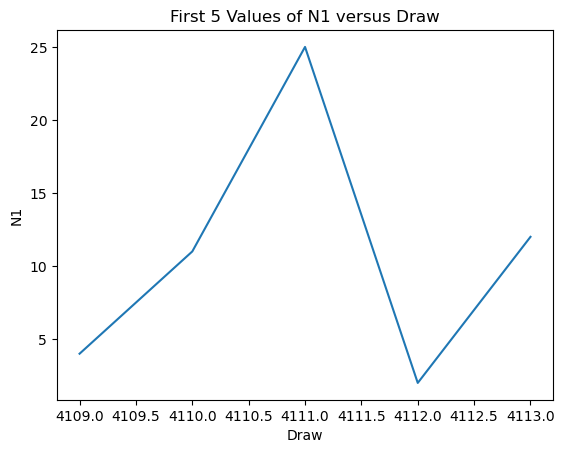

In [54]:
# give a line plot for the first 5 values of N1 versus date in the dataframe df_from_db       

plt.plot(df_from_db['Draw'].head(5), df_from_db['N1'].head(5))
plt.xlabel('Draw')
plt.ylabel('N1')
plt.title('First 5 Values of N1 versus Draw')
plt.show()

In [48]:
n1_values

[12, 2]